# ITCS 6169/8169 — Computer Vision
## Assignment 2: Self-Supervised Visual Representation Learning — Baseline Notebook

A starting point to modify, in the same spirit as the A1 starter CNN. Everything is trained **from scratch on the provided 2,400 images only** (no pretrained weights).

**Pipeline**
1. **Supervised baseline** — your A1 `TNet`, trained with labels only.
2. **SSL pretraining** — `TNet` backbone + projection head, trained on two augmented views of each image (labels never used) with either
   - a **CLIP-style softmax contrastive loss** (InfoNCE across the batch, both directions), or
   - a **SigLIP-style sigmoid loss** (every pair in the batch is an independent binary decision).
3. **Evaluate representations** — frozen-feature **linear probe** (tracked during pretraining), then **supervised fine-tuning**.
4. *(Optional)* **Joint training** — cross-entropy + λ · SSL loss.

**Where to change things:** the `CONFIG` cell (hyperparameters), `ssl_aug` (SSL augmentations), `TNet`/`SSLNet` (architecture), and the loss classes. Set `SMOKE_TEST = True` first to check everything runs end-to-end in a couple of minutes.

**Rules reminder:** no external pretrained weights, no extra images. The test set is **not** used for SSL or for model selection; use validation for decisions and run the test cells once per finalist.

In [1]:
# Core imports
from pathlib import Path
import random
import time
import copy
import math

import numpy as np
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torch.utils.data import DataLoader, random_split
from torchvision import datasets, transforms

try:
    import torch_directml  # to allow for AMD gpu usage
    HAS_DML = torch_directml.is_available()
except ImportError:
    HAS_DML = False

print(f"PyTorch version: {torch.__version__}")
print(f"CUDA available: {torch.cuda.is_available()}")
print(f"DirectML available: {HAS_DML}")

PyTorch version: 2.4.1+cpu
CUDA available: False
DirectML available: True


In [2]:
PROJECT_ROOT = Path('.')
DATA_ROOT = PROJECT_ROOT / 'data'
TRAIN_ROOT = DATA_ROOT / 'train'
TEST_ROOT = DATA_ROOT / 'test'

print('Project root:', PROJECT_ROOT.resolve())
print('Training data:', TRAIN_ROOT)
print('Testing data:', TEST_ROOT)

Project root: D:\School\13 - Fall 2026\ITCS 6169\assignment2
Training data: data\train
Testing data: data\test


In [3]:
SEED = 0

def set_random_seed(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

def get_device():
    """CUDA if available, else DirectML (AMD GPU on Windows), else CPU."""
    if torch.cuda.is_available():
        return torch.device("cuda")
    if HAS_DML:
        return torch_directml.device()
    return torch.device("cpu")

set_random_seed(SEED)
device = get_device()
print('Device:', device)

Device: privateuseone:0


## Config
All the knobs in one place. `SMOKE_TEST = True` shrinks every run to ~2 epochs so you can verify the whole notebook executes before launching long runs.

In [4]:
SMOKE_TEST = False   # True -> tiny runs, just to check the notebook runs end-to-end

# Data
IMG_SIZE = 64
BATCH_SIZE = 32          # supervised / fine-tuning batch size
VAL_FRACTION = 0.20

# Supervised training and fine-tuning (same recipe as your A1 final model)
SUP_EPOCHS = 120 # unused since the best checkpoint from a1 is loaded instead of retraining here, but included to show the full recipe
SUP_LR = 5e-4
SUP_WD = 0.05
MIXUP_ALPHA = 0.4
CUTMIX_ALPHA = 1.0
CUTMIX_PROB = 0.5

# SSL pretraining
SSL_BS = 128             # contrastive batch size (try 32 / 128 / 256 -- SigLIP is claimed to help at small batches)
SSL_EPOCHS = 100         # increase later for final runs
SSL_LR = 1e-3
SSL_WD = 0.05
PROBE_EVERY = 5          # run a linear probe every N SSL epochs
FEAT_DIM = 256           # TNet output width (widths[-1])
PROJ_HIDDEN = 512
PROJ_DIM = 128
FT_EPOCHS = 100          # fine-tuning after SSL pretraining

# Joint supervised + SSL
JOINT_EPOCHS = 100
JOINT_LAMBDA = 1.0

if SMOKE_TEST:
    SUP_EPOCHS = FT_EPOCHS = JOINT_EPOCHS = SSL_EPOCHS = 2
    PROBE_EVERY = 1

IMAGENET_MEAN = [0.485, 0.456, 0.406]   # only used as generic input normalization (no pretrained weights)
IMAGENET_STD = [0.229, 0.224, 0.225]

## Data

In [5]:
# Mixup / CutMix helpers (from A1)
def mixup_data(x, y, alpha=0.2):
    '''Returns mixed inputs, pairs of targets, and lambda.'''
    if alpha > 0:
        lam = np.random.beta(alpha, alpha)
    else:
        lam = 1.0

    batch_size = x.size(0)
    index = torch.randperm(batch_size).to(x.device)

    mixed_x = lam * x + (1 - lam) * x[index]
    y_a, y_b = y, y[index]
    return mixed_x, y_a, y_b, lam

def cutmix_data(x, y, alpha=1.0):
    lam = np.random.beta(alpha, alpha)
    index = torch.randperm(x.size(0), device=x.device)
    H, W = x.size(2), x.size(3)

    cut_ratio = np.sqrt(1.0 - lam)
    cut_h, cut_w = int(H * cut_ratio), int(W * cut_ratio)
    cy, cx = np.random.randint(H), np.random.randint(W)
    y1, y2 = np.clip(cy - cut_h // 2, 0, H), np.clip(cy + cut_h // 2, 0, H)
    x1, x2 = np.clip(cx - cut_w // 2, 0, W), np.clip(cx + cut_w // 2, 0, W)

    x = x.clone()
    x[:, :, y1:y2, x1:x2] = x[index, :, y1:y2, x1:x2]
    lam = 1.0 - ((y2 - y1) * (x2 - x1) / (H * W))   # correct lam for the clipped box
    return x, y, y[index], lam

def mixup_criterion(criterion, pred, y_a, y_b, lam):
    return lam * criterion(pred, y_a) + (1 - lam) * criterion(pred, y_b)

def random_grayscale_rgb(img):
    # Augment only on training; validation/test should stay clean.
    if random.random() < 0.5:
        gray = img.convert("L")
        return gray.convert("RGB")
    return img

In [6]:
import threading, queue

class Prefetch:
    """Runs a DataLoader in a background thread so augmentation overlaps with GPU compute."""
    def __init__(self, loader, depth=3):
        self.loader, self.depth = loader, depth

    def __len__(self):
        return len(self.loader)

    def __iter__(self):
        q = queue.Queue(maxsize=self.depth)
        done = object()
        def work():
            try:
                for item in self.loader:
                    q.put(item)
            except Exception as e:          # hand errors to the main thread instead of hanging it
                q.put(e)
            q.put(done)
        threading.Thread(target=work, daemon=True).start()
        while True:
            item = q.get()
            if item is done:
                return
            if isinstance(item, Exception):
                raise item
            yield item

In [7]:
# Supervised training augmentation (from A1)
train_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.RandomHorizontalFlip(),
    transforms.ColorJitter(brightness=0.1, contrast=0.1, saturation=0.1),
    transforms.Lambda(random_grayscale_rgb),
    transforms.ToTensor(),
    transforms.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD),
])

# Validation/test preprocessing: no randomness.
eval_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD),
])

# SSL augmentation: much stronger than the supervised one. THIS IS THE MAIN THING TO EXPERIMENT WITH.
# Contrastive learning works by making the two views look different while keeping the content the same.
ssl_aug = transforms.Compose([
    transforms.RandomResizedCrop(IMG_SIZE, scale=(0.3, 1.0)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomApply([transforms.ColorJitter(0.4, 0.4, 0.4, 0.1)], p=0.8),
    transforms.RandomGrayscale(p=0.2),
    transforms.ToTensor(),
    transforms.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD),
])

class TransformSubset(torch.utils.data.Dataset):
    def __init__(self, subset, transform):
        self.subset = subset
        self.transform = transform

    def __len__(self):
        return len(self.subset)

    def __getitem__(self, idx):
        image, label = self.subset[idx]
        if self.transform is not None:
            image = self.transform(image)
        return image, label

class TwoView(torch.utils.data.Dataset):
    """Returns two independently augmented views of the same image (plus the label,
    which the SSL loop ignores; only the joint-training section uses it)."""
    def __init__(self, subset, transform):
        self.subset = subset
        self.transform = transform

    def __len__(self):
        return len(self.subset)

    def __getitem__(self, idx):
        image, label = self.subset[idx]
        return self.transform(image), self.transform(image), label

In [8]:
from PIL import Image

base_train_dataset = datasets.ImageFolder(TRAIN_ROOT)
class_names = base_train_dataset.classes
num_classes = len(class_names)

# decode + resize once; random_split below uses the same generator, so the split is identical to before
cached_train = [(img.resize((IMG_SIZE, IMG_SIZE), Image.BILINEAR), y) for img, y in base_train_dataset]

val_size = int(round(len(base_train_dataset) * VAL_FRACTION))
train_size = len(base_train_dataset) - val_size
generator = torch.Generator().manual_seed(SEED)

train_subset, val_subset = random_split(
    cached_train, [train_size, val_size], generator=generator
)

train_dataset = TransformSubset(train_subset, train_transform)
val_dataset = TransformSubset(val_subset, eval_transform)
test_dataset = datasets.ImageFolder(TEST_ROOT, transform=eval_transform)

pin = torch.cuda.is_available()
train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True, num_workers=0, pin_memory=pin)
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=0, pin_memory=pin)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=0, pin_memory=pin)

def make_ssl_loader(bs=None, aug=None):
    """Two-view loader over the TRAIN split only (never val/test). drop_last keeps batches full,
    which both contrastive losses assume."""
    return Prefetch(DataLoader(TwoView(train_subset, aug or ssl_aug), batch_size=bs or SSL_BS,
                               shuffle=True, drop_last=True, num_workers=0, pin_memory=pin))

print(f'Classes ({num_classes}): {class_names}')
print(f'Total training images: {len(base_train_dataset)}')
print(f'Train: {len(train_dataset)} | Validation: {len(val_dataset)} | Test: {len(test_dataset)}')

Classes (16): ['Bedroom', 'Coast', 'Flower', 'Forest', 'Highway', 'Industrial', 'InsideCity', 'Kitchen', 'LivingRoom', 'Mountain', 'Office', 'OpenCountry', 'Store', 'Street', 'Suburb', 'TallBuilding']
Total training images: 2400
Train: 1920 | Validation: 480 | Test: 400


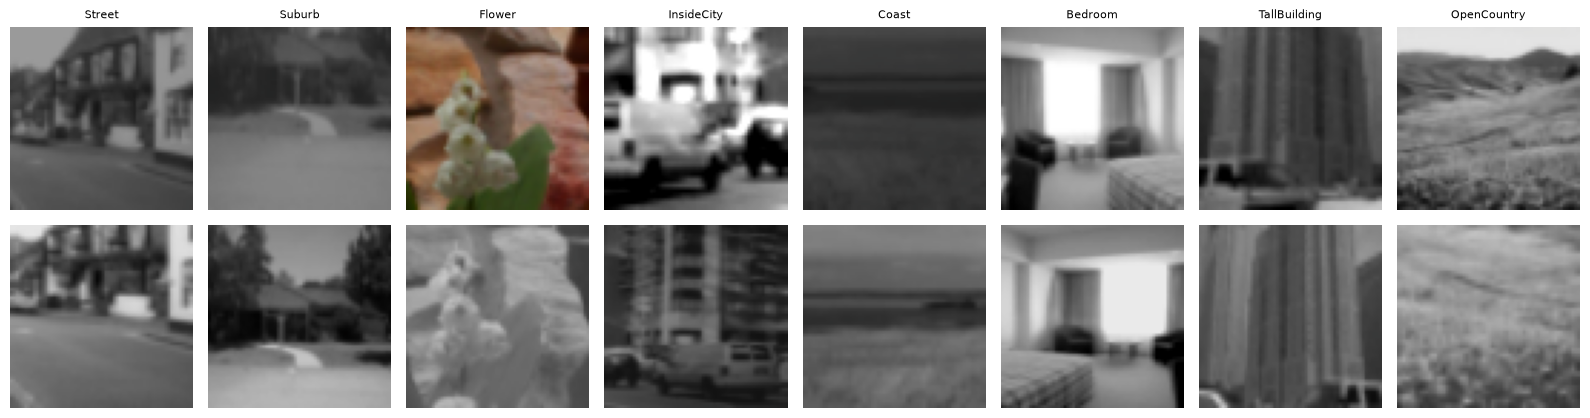

In [9]:
# Sanity check: look at pairs of SSL views. Each column = one image; the two rows are its two views.
# If the views are unrecognizable, the augmentations are too strong; if identical, too weak.
def denorm(t):
    mean = torch.tensor(IMAGENET_MEAN).view(3, 1, 1)
    std = torch.tensor(IMAGENET_STD).view(3, 1, 1)
    return (t.cpu() * std + mean).clamp(0, 1).permute(1, 2, 0).numpy()

v1, v2, y = next(iter(make_ssl_loader(bs=8)))
fig, axes = plt.subplots(2, 8, figsize=(16, 4.4))
for i in range(8):
    axes[0, i].imshow(denorm(v1[i])); axes[0, i].set_title(class_names[y[i].item()], fontsize=8)
    axes[1, i].imshow(denorm(v2[i]))
    axes[0, i].axis('off'); axes[1, i].axis('off')
plt.tight_layout()
plt.show()

## Models
`TNet` is your A1 CNN. `SSLNet` reuses its convolutional stack as the **encoder**, adds global pooling, and attaches a small **projection head**. The contrastive loss is applied on the head's output; for downstream classification the head is thrown away and only the encoder features (`embed`) are used. This is standard practice, since the head tends to discard information the loss doesn't need but classification might.

In [10]:
def conv_bn_relu(in_ch, out_ch):
    return nn.Sequential(
        nn.Conv2d(in_ch, out_ch, kernel_size=3, padding=1, bias=False),
        nn.BatchNorm2d(out_ch),
        nn.ReLU(inplace=True),
    )

class TNet(nn.Module):
    def __init__(self, num_classes=16, widths=(32, 64, 128, 256), dropout=0.3):
        super().__init__()
        c1, c2, c3, c4 = widths

        self.features = nn.Sequential(
            # Stage 1
            conv_bn_relu(3, c1),
            conv_bn_relu(c1, c1),
            nn.MaxPool2d(2),

            # Stage 2
            conv_bn_relu(c1, c2),
            conv_bn_relu(c2, c2),
            nn.MaxPool2d(2),

            # Stage 3
            conv_bn_relu(c2, c3),
            conv_bn_relu(c3, c3),
            nn.MaxPool2d(2),

            conv_bn_relu(c3, c4),
            conv_bn_relu(c4, c4),
        )

        self.classifier = nn.Sequential(
            nn.AdaptiveAvgPool2d((1, 1)),
            nn.Flatten(),
            nn.Dropout(dropout),
            nn.Linear(c4, num_classes),
        )

    def forward(self, x):
        x = self.features(x)
        return self.classifier(x)


class SSLNet(nn.Module):
    """Encoder (TNet conv stack) + global pool + projection head."""
    def __init__(self, feat_dim=FEAT_DIM, hidden=PROJ_HIDDEN, proj_dim=PROJ_DIM):
        super().__init__()
        self.features = TNet(num_classes=num_classes).features   # same structure as the supervised model
        self.pool = nn.Sequential(nn.AdaptiveAvgPool2d((1, 1)), nn.Flatten())
        self.head = nn.Sequential(
            nn.Linear(feat_dim, hidden),
            nn.BatchNorm1d(hidden),
            nn.ReLU(inplace=True),
            nn.Linear(hidden, proj_dim),
        )

    def embed(self, x):          # representation used for probing / fine-tuning
        return self.pool(self.features(x))

    def forward(self, x):        # projection used by the SSL loss
        return self.head(self.embed(x))


model = TNet(num_classes=num_classes)
print(f'TNet trainable parameters: {sum(p.numel() for p in model.parameters() if p.requires_grad):,}')
print(f'SSLNet trainable parameters: {sum(p.numel() for p in SSLNet().parameters() if p.requires_grad):,}')

TNet trainable parameters: 1,177,328
SSLNet trainable parameters: 1,371,488


## SSL losses
Both take two batches of projections `z1, z2` (row *i* of each comes from the same image) and pull matching pairs together while pushing non-matching pairs apart. They differ only in **how** the n×n similarity matrix is scored:

- **CLIP-style (softmax / InfoNCE):** each row (and column) is an n-way classification problem — "which of the n candidates is my partner?" Every negative competes against every other in the same softmax, so the loss depends on batch size.
- **SigLIP-style (sigmoid):** each of the n² entries is an independent binary decision (+1 on the diagonal, −1 elsewhere). There is no normalization across the batch. A learnable bias `b` (initialized to −10) accounts for there being n positives vs. n²−n negatives.

Both use a learnable temperature. Note there are **no captions** here, so these are SimCLR-style two-view versions of the CLIP and SigLIP objectives, not the original image-text models.

In [11]:
class CLIPStyleLoss(nn.Module):
    """Symmetric softmax contrastive loss (InfoNCE) with learnable temperature."""
    def __init__(self, init_temp=0.07):
        super().__init__()
        self.log_scale = nn.Parameter(torch.tensor(math.log(1.0 / init_temp)))

    def forward(self, z1, z2):
        z1, z2 = F.normalize(z1, dim=1), F.normalize(z2, dim=1)
        logits = self.log_scale.exp().clamp(max=100.0) * (z1 @ z2.T)
        y = torch.arange(len(z1), device=z1.device)
        return (F.cross_entropy(logits, y) + F.cross_entropy(logits.T, y)) / 2


class SigLIPStyleLoss(nn.Module):
    """Pairwise sigmoid loss: +1 label for matching pairs, -1 for every other pair in the batch."""
    def __init__(self, init_t=10.0, init_b=-10.0):
        super().__init__()
        self.log_t = nn.Parameter(torch.tensor(math.log(init_t)))
        self.b = nn.Parameter(torch.tensor(float(init_b)))

    def forward(self, z1, z2):
        z1, z2 = F.normalize(z1, dim=1), F.normalize(z2, dim=1)
        logits = self.log_t.exp() * (z1 @ z2.T) + self.b
        labels = (2 * torch.eye(len(z1)) - 1).to(z1.device)   # build on CPU: torch.eye is broken on DirectML
        return -F.logsigmoid(labels * logits).sum() / len(z1)

## Training utilities
`evaluate` and `train_model` are your A1 versions. The only change: the LR `scheduler` is now an argument instead of a notebook global.

In [12]:
@torch.no_grad()
def evaluate(model, loader, device):
    model.eval()
    correct = 0
    total = 0
    running_loss = 0.0
    criterion = nn.CrossEntropyLoss()

    for images, labels in loader:
        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)
        logits = model(images)
        loss = criterion(logits, labels)
        running_loss += loss.item() * images.size(0)
        correct += (logits.argmax(dim=1) == labels).sum().item()
        total += labels.size(0)

    return running_loss / total, correct / total


def train_model(model, train_loader, val_loader, optimizer, scheduler=None, epochs=20, device=device,
                mixup_alpha=0.0, cutmix_alpha=1.0, cutmix_prob=0.0):
    criterion = nn.CrossEntropyLoss()
    model = model.to(device)
    best_state = copy.deepcopy(model.state_dict())
    best_val_acc = 0.0
    history = {'train_loss': [], 'val_loss': [], 'val_acc': []}
    start = time.time()

    for epoch in range(1, epochs + 1):
        model.train()
        total_loss = 0.0
        total_seen = 0

        for images, labels in train_loader:
            images = images.to(device, non_blocking=True)
            labels = labels.to(device, non_blocking=True)

            optimizer.zero_grad(set_to_none=True)

            # Pick at most one mixing method per batch
            use_cutmix = cutmix_prob > 0 and np.random.rand() < cutmix_prob
            use_mixup = (not use_cutmix) and mixup_alpha > 0

            if use_cutmix:
                images, labels_a, labels_b, lam = cutmix_data(images, labels, alpha=cutmix_alpha)
            elif use_mixup:
                images, labels_a, labels_b, lam = mixup_data(images, labels, alpha=mixup_alpha)

            logits = model(images)
            if use_cutmix or use_mixup:
                loss = mixup_criterion(criterion, logits, labels_a, labels_b, lam)
            else:
                loss = criterion(logits, labels)

            loss.backward()
            optimizer.step()

            total_loss += loss.item() * images.size(0)
            total_seen += labels.size(0)

        train_loss = total_loss / total_seen
        val_loss, val_acc = evaluate(model, val_loader, device)
        history['train_loss'].append(train_loss)
        history['val_loss'].append(val_loss)
        history['val_acc'].append(val_acc)

        if scheduler is not None:
            scheduler.step()

        if val_acc > best_val_acc:
            best_val_acc = val_acc
            best_state = copy.deepcopy(model.state_dict())

        elapsed = time.time() - start
        print(f'Epoch {epoch:02d}/{epochs} | '
              f'train loss {train_loss:.4f} | val loss {val_loss:.4f} | '
              f'val acc {val_acc:.4f} | {elapsed:.1f}s')

    last_state = copy.deepcopy(model.state_dict())
    model.load_state_dict(best_state)
    print(f'Best validation accuracy: {best_val_acc:.4f}')
    return model, history, best_state, last_state

In [13]:
# ---- Linear probe: how good are the frozen features? ----
@torch.no_grad()
def embed_dataset(net, loader):
    net.eval()
    feats, ys = [], []
    for x, y in loader:
        feats.append(net.embed(x.to(device)).cpu())
        ys.append(y)
    return torch.cat(feats), torch.cat(ys)

def linear_probe(net, steps=300, lr=1e-2, wd=1e-4):
    """Train a single linear layer on FROZEN encoder features (train split, no augmentation)
    and report validation accuracy. Runs on CPU on cached features, so it is cheap."""
    train_clean = DataLoader(TransformSubset(train_subset, eval_transform), batch_size=128, shuffle=False)
    ftr, ytr = embed_dataset(net, train_clean)
    fva, yva = embed_dataset(net, val_loader)
    mu, sd = ftr.mean(0), ftr.std(0) + 1e-6
    ftr, fva = (ftr - mu) / sd, (fva - mu) / sd

    clf = nn.Linear(ftr.shape[1], num_classes)
    opt = optim.AdamW(clf.parameters(), lr=lr, weight_decay=wd)
    for _ in range(steps):
        opt.zero_grad()
        F.cross_entropy(clf(ftr), ytr).backward()
        opt.step()
    with torch.no_grad():
        return (clf(fva).argmax(1) == yva).float().mean().item()

In [14]:
# checkpoint saving and loading

CKPT_DIR = PROJECT_ROOT / 'checkpoints'
CKPT_DIR.mkdir(exist_ok=True)

def slug(name):
    """'SSL CLIP-style' -> 'ssl_clip_style'"""
    return ''.join(c.lower() if c.isalnum() else '_' for c in name).strip('_')

def cpu_state(sd):
    """Detached CPU copy of a state dict (safe to keep around and to save)."""
    return {k: v.detach().cpu().clone() for k, v in sd.items()}

def save_ckpt(name, stage, best_state, last_state, **extra):
    """Write checkpoints/<slug>_<stage>.pt containing best_state, last_state and any extras.
    Writes to a temp file first so a crash mid-write can't corrupt the previous checkpoint."""
    path = CKPT_DIR / f'{slug(name)}_{stage}.pt'
    tmp = path.with_suffix('.tmp')
    torch.save({'best_state': best_state, 'last_state': last_state, **extra}, tmp)
    tmp.replace(path)
    return path

def load_ckpt(name, stage, which='best'):
    ck = torch.load(CKPT_DIR / f'{slug(name)}_{stage}.pt', map_location='cpu')
    return ck[f'{which}_state'], ck          # which = 'best' or 'last'

def load_pretrained(name, which='best'):
    """Rebuild a pretrained SSLNet (encoder + projection head) from a checkpoint."""
    sd, _ = load_ckpt(name, 'pretrain', which)
    net = SSLNet()
    net.load_state_dict(sd)
    return net.to(device)

def load_finetuned(name, which='best'):
    """Rebuild a fine-tuned TNet classifier from a checkpoint."""
    sd, _ = load_ckpt(name, 'finetune', which)
    model = TNet(num_classes=num_classes)
    model.load_state_dict(sd)
    return model.to(device)

In [15]:
def ssl_pretrain(loss_fn, bs=None, epochs=None, lr=None, wd=None, seed=SEED,
                 probe_every=None, aug=None, name='', save=True, print_every=1):
    """SSL pretraining on two-view batches. Labels are never used. Returns (net, log).
    Prints a line every `print_every` epochs (and on every probe epoch). If save=True and name is
    given, checkpoints/<name>_pretrain.pt is updated at every probe (best-probe + latest weights)."""
    bs, epochs = bs or SSL_BS, epochs or SSL_EPOCHS
    lr, wd = lr or SSL_LR, wd if wd is not None else SSL_WD
    probe_every = probe_every or PROBE_EVERY

    set_random_seed(seed)
    net, loss_fn = SSLNet().to(device), loss_fn.to(device)
    loader = make_ssl_loader(bs, aug)

    # loss params (temperature / bias) get no weight decay
    opt = optim.AdamW([{'params': net.parameters(), 'weight_decay': wd},
                       {'params': loss_fn.parameters(), 'weight_decay': 0.0}], lr=lr)
    sched = optim.lr_scheduler.CosineAnnealingLR(opt, T_max=epochs)

    log = {'loss': [], 'probe_epoch': [], 'probe_acc': []}
    best_probe, best_epoch, best_state = -1.0, 0, None
    hparams = dict(loss=type(loss_fn).__name__, bs=bs, epochs=epochs, lr=lr, wd=wd, seed=seed)
    start = time.time()
    for ep in range(1, epochs + 1):
        net.train()
        tot, n = 0.0, 0
        for v1, v2, _ in loader:                         # label ignored
            x = torch.cat([v1, v2]).to(device)           # one forward pass -> consistent BatchNorm stats
            z1, z2 = net(x).chunk(2)
            loss = loss_fn(z1, z2)
            opt.zero_grad(set_to_none=True)
            loss.backward()
            opt.step()
            tot += loss.item(); n += 1
        sched.step()
        avg = tot / n
        log['loss'].append(avg)

        line = f'[{name}] ep {ep:03d}/{epochs} | ssl loss {avg:.4f}'
        do_probe = (ep % probe_every == 0) or (ep == epochs)
        if do_probe:
            acc = linear_probe(net)
            log['probe_epoch'].append(ep); log['probe_acc'].append(acc)
            if acc > best_probe:
                best_probe, best_epoch, best_state = acc, ep, cpu_state(net.state_dict())
            params = ', '.join(f'{k}={v.item():.2f}' for k, v in loss_fn.named_parameters())
            line += f' | probe val acc {acc:.4f} (best {best_probe:.4f} @ {best_epoch}) | {params}'
            if save and name:
                save_ckpt(name, 'pretrain', best_state, cpu_state(net.state_dict()),
                          loss_state=cpu_state(loss_fn.state_dict()), log=log, hparams=hparams,
                          best_probe_acc=best_probe, best_probe_epoch=best_epoch, last_epoch=ep)
        line += f' | {time.time()-start:.0f}s'
        if do_probe or ep % print_every == 0:
            print(line)

    log['best_probe_acc'], log['best_probe_epoch'] = best_probe, best_epoch
    if save and name:
        print(f"Saved pretraining checkpoint: {CKPT_DIR / (slug(name) + '_pretrain.pt')}")
    return net, log


def finetune(net=None, epochs=None, lr=None):
    """net=None -> plain supervised training from a fresh TNet (the baseline); otherwise start from net's encoder."""
    epochs, lr = epochs or FT_EPOCHS, lr or SUP_LR
    model = TNet(num_classes=num_classes)
    if net is not None:
        # go through CPU copies: loading the DirectML state dict directly leaves the weights with requires_grad=False
        model.features.load_state_dict({k: v.detach().cpu().clone() for k, v in net.features.state_dict().items()})
    model = model.to(device)
    assert all(p.requires_grad for p in model.parameters()), 'some parameters are frozen'
    optimizer = optim.AdamW(model.parameters(), lr=lr, weight_decay=SUP_WD)
    scheduler = optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=epochs)
    return train_model(model, train_loader, val_loader, optimizer, scheduler=scheduler, epochs=epochs,
                       device=device, mixup_alpha=MIXUP_ALPHA, cutmix_alpha=CUTMIX_ALPHA, cutmix_prob=CUTMIX_PROB)

In [16]:
# Bookkeeping: everything you run gets logged here so you can build the report table at the end.
results = {}      # name -> dict of validation numbers
models = {}       # name -> trained model (best-val weights), for the test-set evaluation at the end
probe_logs = {}   # name -> SSL pretraining log (loss + probe curve)

def record(name, history, model, probe_acc=None, note=''):
    results[name] = {
        'val_best': max(history['val_acc']),
        'val_last': history['val_acc'][-1],
        'probe_val': probe_acc,
        'note': note,
    }
    models[name] = model
    print(f"Logged '{name}': best val {results[name]['val_best']:.4f}, last val {results[name]['val_last']:.4f}")

def run_ssl_experiment(name, loss_fn, note='', save=True, **ssl_kwargs):
    """SSL pretrain -> linear probe -> supervised fine-tune. Logs everything and saves checkpoints."""
    net, log = ssl_pretrain(loss_fn, name=name, save=save, **ssl_kwargs)
    probe_logs[name] = log
    set_random_seed(SEED)
    model, hist, ft_best, ft_last = finetune(net)
    if save:
        path = save_ckpt(name, 'finetune', cpu_state(ft_best), cpu_state(ft_last), history=hist,
                        hparams=dict(epochs=FT_EPOCHS, lr=SUP_LR, wd=SUP_WD, mixup_alpha=MIXUP_ALPHA,
                        cutmix_alpha=CUTMIX_ALPHA, cutmix_prob=CUTMIX_PROB, seed=SEED))
        print('Saved fine-tuned checkpoint:', path)
    record(f'{name} + finetune', hist, model, probe_acc=log['probe_acc'][-1], note=note)
    return net, model, hist

## Experiment 1: Supervised baseline

In [17]:
TRAIN_BASELINE = True    # set to False after the first run: the cell then loads the saved checkpoint instead of retraining
BASELINE_NAME = 'supervised baseline (64px)'
BASELINE_EPOCHS = FT_EPOCHS   # keep equal to FT_EPOCHS so the SSL fine-tunes are a like-for-like comparison

if TRAIN_BASELINE:
    set_random_seed(SEED)
    base_model, base_hist, base_best, base_last = finetune(None, epochs=BASELINE_EPOCHS)
    save_ckpt(BASELINE_NAME, 'train', cpu_state(base_best), cpu_state(base_last), history=base_hist,
              hparams=dict(img_size=IMG_SIZE, epochs=BASELINE_EPOCHS, lr=SUP_LR, wd=SUP_WD,
                           mixup_alpha=MIXUP_ALPHA, cutmix_alpha=CUTMIX_ALPHA, cutmix_prob=CUTMIX_PROB,
                           batch_size=BATCH_SIZE, seed=SEED))
    print('Saved baseline checkpoint to', CKPT_DIR)
else:
    sd, ck = load_ckpt(BASELINE_NAME, 'train', 'best')
    assert ck['hparams']['img_size'] == IMG_SIZE, \
        f"checkpoint was trained at {ck['hparams']['img_size']}px but IMG_SIZE is {IMG_SIZE}"
    base_model = TNet(num_classes=num_classes)
    base_model.load_state_dict(sd)
    base_model = base_model.to(device)
    base_hist = ck['history']

record(BASELINE_NAME, base_hist, base_model,
       note='trained here' if TRAIN_BASELINE else 'loaded from checkpoint')

c:\Users\Bryan\AppData\Local\Programs\Python\Python311\Lib\site-packages\torch\optim\adamw.py:529: UserWarning: The operator 'aten::lerp.Scalar_out' is not currently supported on the DML backend and will fall back to run on the CPU. This may have performance implications. (Triggered internally at C:\__w\1\s\pytorch-directml-plugin\torch_directml\csrc\dml\dml_cpu_fallback.cpp:17.)
  torch._foreach_lerp_(device_exp_avgs, device_grads, 1 - beta1)


Epoch 01/100 | train loss 2.4425 | val loss 1.9645 | val acc 0.3792 | 3.4s
Epoch 02/100 | train loss 2.1979 | val loss 1.8411 | val acc 0.3917 | 6.5s
Epoch 03/100 | train loss 2.0298 | val loss 1.4774 | val acc 0.5333 | 9.7s
Epoch 04/100 | train loss 1.8754 | val loss 1.3716 | val acc 0.5771 | 12.8s
Epoch 05/100 | train loss 1.8084 | val loss 1.2843 | val acc 0.5833 | 16.0s
Epoch 06/100 | train loss 1.7859 | val loss 1.7407 | val acc 0.4271 | 19.3s
Epoch 07/100 | train loss 1.6732 | val loss 1.2559 | val acc 0.5667 | 22.5s
Epoch 08/100 | train loss 1.6794 | val loss 1.0891 | val acc 0.6375 | 25.4s
Epoch 09/100 | train loss 1.5868 | val loss 0.9723 | val acc 0.6708 | 28.2s
Epoch 10/100 | train loss 1.5812 | val loss 0.9259 | val acc 0.7021 | 30.9s
Epoch 11/100 | train loss 1.5914 | val loss 0.9865 | val acc 0.6667 | 34.0s
Epoch 12/100 | train loss 1.5051 | val loss 1.0209 | val acc 0.6833 | 37.0s
Epoch 13/100 | train loss 1.5573 | val loss 0.9602 | val acc 0.7000 | 40.2s
Epoch 14/100 | 

## Experiment 2: SSL with a CLIP-style (softmax) loss, then fine-tune
Watch the printed **probe val acc**: it measures how much class information the encoder has learned *without ever seeing a label*. Random chance is 1/16 ≈ 6%. An untrained (random) encoder usually still scores well above chance, so compare against that, not just against zero.

In [18]:
net_clip, model_clip, hist_clip = run_ssl_experiment(
    'SSL CLIP-style', CLIPStyleLoss(), note=f'softmax loss, bs={SSL_BS}')

[SSL CLIP-style] ep 001/100 | ssl loss 4.0363 | 3s
[SSL CLIP-style] ep 002/100 | ssl loss 2.9992 | 6s
[SSL CLIP-style] ep 003/100 | ssl loss 2.4137 | 9s
[SSL CLIP-style] ep 004/100 | ssl loss 2.0048 | 12s
[SSL CLIP-style] ep 005/100 | ssl loss 1.6764 | probe val acc 0.5562 (best 0.5562 @ 5) | log_scale=2.67 | 15s
[SSL CLIP-style] ep 006/100 | ssl loss 1.5142 | 18s
[SSL CLIP-style] ep 007/100 | ssl loss 1.2483 | 21s
[SSL CLIP-style] ep 008/100 | ssl loss 1.1744 | 23s
[SSL CLIP-style] ep 009/100 | ssl loss 1.0003 | 26s
[SSL CLIP-style] ep 010/100 | ssl loss 0.8995 | probe val acc 0.6104 (best 0.6104 @ 10) | log_scale=2.69 | 30s
[SSL CLIP-style] ep 011/100 | ssl loss 0.9034 | 32s
[SSL CLIP-style] ep 012/100 | ssl loss 0.8559 | 35s
[SSL CLIP-style] ep 013/100 | ssl loss 0.8031 | 38s
[SSL CLIP-style] ep 014/100 | ssl loss 0.7125 | 41s
[SSL CLIP-style] ep 015/100 | ssl loss 0.6171 | probe val acc 0.6208 (best 0.6208 @ 15) | log_scale=2.73 | 44s
[SSL CLIP-style] ep 016/100 | ssl loss 0.6452 |

## Experiment 3: SSL with a SigLIP-style (sigmoid) loss, then fine-tune
Identical to Experiment 2 except for the loss, so any difference is attributable to the loss (up to seed noise; with 480 validation images one standard error is ~1.4%, so treat gaps below 2–3% as noise unless you repeat with several seeds).

In [19]:
net_sig, model_sig, hist_sig = run_ssl_experiment(
    'SSL SigLIP-style', SigLIPStyleLoss(), note=f'sigmoid loss, bs={SSL_BS}')

[SSL SigLIP-style] ep 001/100 | ssl loss 5.1474 | 3s
[SSL SigLIP-style] ep 002/100 | ssl loss 3.7536 | 6s
[SSL SigLIP-style] ep 003/100 | ssl loss 3.3059 | 8s
[SSL SigLIP-style] ep 004/100 | ssl loss 3.0160 | 11s
[SSL SigLIP-style] ep 005/100 | ssl loss 2.8399 | probe val acc 0.5625 (best 0.5625 @ 5) | log_t=2.31, b=-9.99 | 15s
[SSL SigLIP-style] ep 006/100 | ssl loss 2.7128 | 17s
[SSL SigLIP-style] ep 007/100 | ssl loss 2.4905 | 20s
[SSL SigLIP-style] ep 008/100 | ssl loss 2.4180 | 23s
[SSL SigLIP-style] ep 009/100 | ssl loss 2.2208 | 26s
[SSL SigLIP-style] ep 010/100 | ssl loss 2.0814 | probe val acc 0.5979 (best 0.5979 @ 10) | log_t=2.38, b=-9.93 | 29s
[SSL SigLIP-style] ep 011/100 | ssl loss 2.0262 | 32s
[SSL SigLIP-style] ep 012/100 | ssl loss 1.9665 | 35s
[SSL SigLIP-style] ep 013/100 | ssl loss 1.8501 | 37s
[SSL SigLIP-style] ep 014/100 | ssl loss 1.7651 | 40s
[SSL SigLIP-style] ep 015/100 | ssl loss 1.6591 | probe val acc 0.6125 (best 0.6125 @ 15) | log_t=2.44, b=-9.88 | 44s
[S

## Experiment 4 (optional): Joint supervised + SSL training
One network, one optimizer: `loss = CE(classifier(embed(x)), y) + λ · SSL_loss(z1, z2)`. The classifier sees both views of every image.

In [21]:
class JointNet(nn.Module):
    def __init__(self):
        super().__init__()
        self.ssl = SSLNet()
        self.classifier = nn.Sequential(nn.Dropout(0.3), nn.Linear(FEAT_DIM, num_classes))

    def forward(self, x):                 # classification only (used by evaluate())
        return self.classifier(self.ssl.embed(x))

    def joint_forward(self, x):           # (class logits, projections)
        e = self.ssl.embed(x)
        return self.classifier(e), self.ssl.head(e)


def train_joint(loss_fn, lam=None, epochs=None, bs=None, lr=None, seed=SEED, name='joint',
                save=True, save_every=10):
    """CE + lam * SSL loss on two views. Saves checkpoints/<name>_train.pt (best-val and latest
    weights) whenever validation accuracy improves, every `save_every` epochs, and at the end."""
    lam = JOINT_LAMBDA if lam is None else lam
    epochs, bs, lr = epochs or JOINT_EPOCHS, bs or SSL_BS, lr or SSL_LR
    set_random_seed(seed)
    net, loss_fn = JointNet().to(device), loss_fn.to(device)
    loader = make_ssl_loader(bs)
    opt = optim.AdamW([{'params': net.parameters(), 'weight_decay': SSL_WD},
                        {'params': loss_fn.parameters(), 'weight_decay': 0.0}], lr=lr)
    sched = optim.lr_scheduler.CosineAnnealingLR(opt, T_max=epochs)

    history = {'train_loss': [], 'val_loss': [], 'val_acc': []}
    hparams = dict(loss=type(loss_fn).__name__, lam=lam, bs=bs, epochs=epochs, lr=lr, wd=SSL_WD, seed=seed)
    best_acc, best_epoch, best_state, start = 0.0, 0, cpu_state(net.state_dict()), time.time()

    for ep in range(1, epochs + 1):
        net.train()
        tot, n = 0.0, 0
        for v1, v2, y in loader:
            x, y = torch.cat([v1, v2]).to(device), torch.cat([y, y]).to(device)
            logits, z = net.joint_forward(x)
            z1, z2 = z.chunk(2)
            loss = F.cross_entropy(logits, y) + lam * loss_fn(z1, z2)
            opt.zero_grad(set_to_none=True)
            loss.backward()
            opt.step()
            tot += loss.item(); n += 1
        sched.step()
        vl, va = evaluate(net, val_loader, device)
        history['train_loss'].append(tot / n); history['val_loss'].append(vl); history['val_acc'].append(va)

        improved = va > best_acc
        if improved:
            best_acc, best_epoch, best_state = va, ep, cpu_state(net.state_dict())
        print(f'[{name}] ep {ep:03d}/{epochs} | loss {tot/n:.4f} | val acc {va:.4f} '
                f'(best {best_acc:.4f} @ {best_epoch}) | {time.time()-start:.0f}s')

        if save and (improved or ep % save_every == 0 or ep == epochs):
            save_ckpt(name, 'train', best_state, cpu_state(net.state_dict()),
                        loss_state=cpu_state(loss_fn.state_dict()), history=history, hparams=hparams,
                        best_val_acc=best_acc, best_epoch=best_epoch, last_epoch=ep)

    net.load_state_dict(best_state)       # return the best-validation weights
    print(f'Best validation accuracy: {best_acc:.4f} (epoch {best_epoch})')
    if save:
        print('Saved joint checkpoint:', CKPT_DIR / f'{slug(name)}_train.pt')
    return net, history


def load_joint(name, which='best'):
    """Rebuild a JointNet from checkpoints/<name>_train.pt (which = 'best' or 'last')."""
    sd, ck = load_ckpt(name, 'train', which)
    net = JointNet()
    net.load_state_dict(sd)
    return net.to(device), ck['history']

# Uncomment to run:
# joint_net, joint_hist = train_joint(SigLIPStyleLoss(), name='joint SigLIP-style')
# record('joint SigLIP-style', joint_hist, joint_net, note=f'CE + {JOINT_LAMBDA} * SigLIP loss')

## Results so far (validation)

Experiment                    val best  val last  probe val   note
supervised baseline (64px)      0.8521    0.8438          -   trained here
SSL CLIP-style + finetune       0.8354    0.8354     0.6792   softmax loss, bs=128
SSL SigLIP-style + finetune     0.8625    0.8625     0.6729   sigmoid loss, bs=128


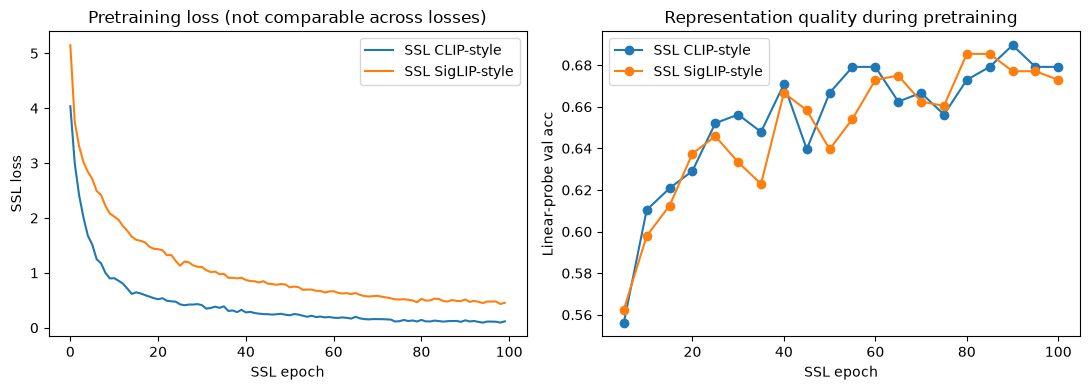

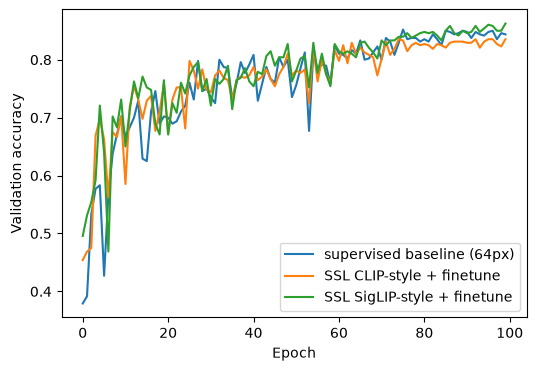

In [22]:
# Summary table of everything logged so far
print(f"{'Experiment':<28}{'val best':>10}{'val last':>10}{'probe val':>11}   note")
for name, r in results.items():
    probe = f"{r['probe_val']:.4f}" if r['probe_val'] is not None else '   -'
    print(f"{name:<28}{r['val_best']:>10.4f}{r['val_last']:>10.4f}{probe:>11}   {r['note']}")

# SSL pretraining curves: loss and linear-probe accuracy
if probe_logs:
    fig, ax = plt.subplots(1, 2, figsize=(11, 4))
    for name, log in probe_logs.items():
        ax[0].plot(log['loss'], label=name)
        ax[1].plot(log['probe_epoch'], log['probe_acc'], marker='o', label=name)
    ax[0].set_xlabel('SSL epoch'); ax[0].set_ylabel('SSL loss'); ax[0].set_title('Pretraining loss (not comparable across losses)')
    ax[1].set_xlabel('SSL epoch'); ax[1].set_ylabel('Linear-probe val acc'); ax[1].set_title('Representation quality during pretraining')
    for a in ax: a.legend()
    plt.tight_layout(); plt.show()

# Supervised vs fine-tuned validation curves
plt.figure(figsize=(6, 4))
plt.plot(base_hist['val_acc'], label='supervised baseline (64px)')
for name, h in [('SSL CLIP-style + finetune', globals().get('hist_clip')), ('SSL SigLIP-style + finetune', globals().get('hist_sig'))]:
    if h is not None:
        plt.plot(h['val_acc'], label=name)
plt.xlabel('Epoch'); plt.ylabel('Validation accuracy'); plt.legend(); plt.show()

## Experiment log (fill this in)
Copy the format from A1. Use **test** accuracy for the final report table; use validation for decisions.

| Experiment | What changed? | Why did you try it? | Val acc (best, last) | Test acc | What did you learn? |
|---|---|---|---|---|---|
| Supervised baseline | Nothing | Baseline | | | |
| SSL CLIP-style + finetune | | | | | |
| SSL SigLIP-style + finetune | | | | | |
| | | | | | |

## Final test-set evaluation
**Run this once per finalist model**, after you have made all decisions on validation. Choosing hyperparameters by looking at these numbers would make the reported test accuracy optimistic.

In [23]:
print(f"{'Model':<28}{'test loss':>11}{'test acc':>10}")
for name, m in models.items():
    tl, ta = evaluate(m, test_loader, device)
    print(f'{name:<28}{tl:>11.4f}{ta:>10.4f}')

Model                         test loss  test acc
supervised baseline (64px)       0.7126    0.8000
SSL CLIP-style + finetune        0.7152    0.7850
SSL SigLIP-style + finetune      0.6839    0.8250


Validation (supervised) overall accuracy: 0.8521

Class             Acc     N   Most confused with
OpenCountry     0.607    28   Coast
Store           0.710    31   Kitchen
LivingRoom      0.731    26   Bedroom
Industrial      0.759    29   Flower
InsideCity      0.800    30   Industrial
Street          0.844    32   Highway
Bedroom         0.846    39   LivingRoom
Mountain        0.857    28   Flower
Kitchen         0.867    30   Bedroom
Office          0.875    24   Bedroom
Highway         0.893    28   Coast
TallBuilding    0.929    28   Industrial
Coast           0.939    33   Forest
Forest          0.966    29   Flower
Suburb          0.971    34   LivingRoom
Flower          1.000    31   -


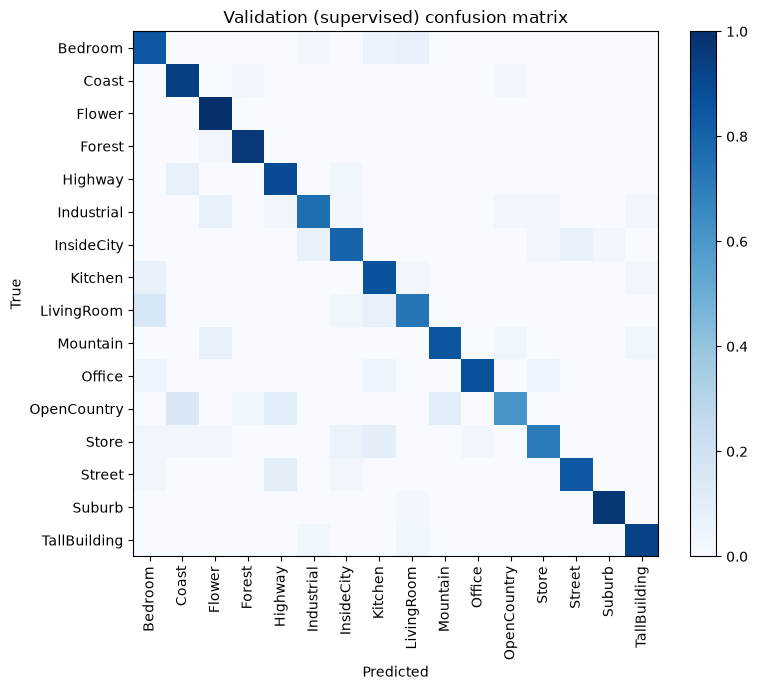

In [25]:
# Per-class analysis (from A1). Use validation for decisions; switch to test_loader only for the final model.
@torch.no_grad()
def get_predictions(model, loader, device):
    model.eval()
    all_preds, all_labels = [], []
    for images, labels in loader:
        logits = model(images.to(device))
        all_preds.append(logits.argmax(dim=1).cpu())
        all_labels.append(labels)
    return torch.cat(all_preds).numpy(), torch.cat(all_labels).numpy()

def per_class_report(model, loader, class_names, device, title=''):
    preds, labels = get_predictions(model, loader, device)
    n = len(class_names)

    # Confusion matrix: rows = true class, cols = predicted class
    cm = np.zeros((n, n), dtype=int)
    for t, p in zip(labels, preds):
        cm[t, p] += 1

    support = cm.sum(axis=1)
    per_class_acc = cm.diagonal() / np.maximum(support, 1)

    print(f'{title} overall accuracy: {(preds == labels).mean():.4f}\n')
    print(f'{"Class":<14}{"Acc":>7}{"N":>6}   Most confused with')
    for i in np.argsort(per_class_acc):  # worst classes first
        off = cm[i].copy()
        off[i] = 0
        confused = class_names[off.argmax()] if off.sum() > 0 else '-'
        print(f'{class_names[i]:<14}{per_class_acc[i]:>7.3f}{support[i]:>6}   {confused}')

    fig, ax = plt.subplots(figsize=(8, 7))
    im = ax.imshow(cm / np.maximum(support[:, None], 1), cmap='Blues', vmin=0, vmax=1)
    ax.set_xticks(range(n)); ax.set_xticklabels(class_names, rotation=90)
    ax.set_yticks(range(n)); ax.set_yticklabels(class_names)
    ax.set_xlabel('Predicted'); ax.set_ylabel('True')
    ax.set_title(f'{title} confusion matrix')
    plt.colorbar(im, fraction=0.046)
    plt.tight_layout()
    plt.show()
    return cm, per_class_acc

cm_val, acc_val = per_class_report(models['supervised baseline (64px)'], val_loader, class_names, device, 'Validation (supervised)')

## Ideas for what to change next
- **Augmentations** (`ssl_aug`): crop scale range, color-jitter strength, blur; ablate one at a time. Which augmentation matters most for *this* dataset?
- **Batch size** (`SSL_BS`): rerun Experiments 2 and 3 at 32 / 128 / 256. Does the sigmoid loss help more at small batches?
- **Temperature / bias init:** fixed vs. learnable, different starting values.
- **Schedule:** more SSL epochs (does the probe curve plateau?), warmup, different LR.
- **Architecture:** wider/deeper encoder, a ResNet-style backbone, or a small ViT trained from scratch. Does the benefit of SSL depend on the backbone?
- **Fine-tuning strategy:** lower LR for the pretrained encoder, freeze early layers, or skip mixup/CutMix after SSL.
- **Joint vs. sequential:** Experiment 4, sweeping `JOINT_LAMBDA`.
- **Other objectives:** rotation prediction, masked-image modeling, or a non-contrastive method (BYOL/SimSiam/DINO-style) for comparison.
- **Seeds:** repeat the key comparisons with 2–3 seeds before claiming one method beats another.